# 08 · Viabilidad del modelo WELLTUR

Pruebas de que el modelo funciona y de qué tan lejos puede llegar con los datos actuales. **Todo se evalúa fuera de muestra:** cada persona se predice con un modelo que no la vio al entrenar (validación cruzada).

1. **Matriz de confusión y curva ROC** del efecto validado: ¿el estrés anticipa quién elegirá relajación o meditación?
2. **Calibración:** ¿las probabilidades del modelo coinciden con lo observado?
3. **Matriz de confusión del recomendador:** tipos recomendados (top 3) contra tipos elegidos, frente a la popularidad y al azar.
4. **Curva de aprendizaje y análisis de potencia:** cuántas personas hacen falta para personalizar más.
5. **Diagrama del flujo completo:** de la encuesta a la recomendación en la app.

In [1]:
import sys, json, math
from pathlib import Path
SRC = next(p for p in [Path('src'), Path('../src'), Path('MODELO/src')] if (p / 'encuesta_etl.py').exists()).resolve()
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from scipy.stats import norm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold, KFold
from lab_graficas import aplicar_estilo, guardar, SERIES, TEXTO, TEXTO_2, ETIQUETAS_PREF
from encuesta_etl import OUT_DEFAULT, PREFERENCIAS
from modelo_preferencias import ndcg_at_k
aplicar_estilo()
df = pd.read_csv(OUT_DEFAULT)
d = df.dropna(subset=['estres_0_100']).reset_index(drop=True)
print('personas con índice de estrés:', len(d))

personas con índice de estrés: 126


## 1. Matriz de confusión: estrés → elige relajación (fuera de muestra)

In [2]:
X, y = d[['estres_0_100']].to_numpy(), d['pref_relajacion'].to_numpy()
prob = np.zeros(len(d)); reps = 50
for r in range(reps):
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=r).split(X, y):
        prob[te] += LogisticRegression().fit(X[tr], y[tr]).predict_proba(X[te])[:, 1] / reps
umbral = y.mean()  # se predice "sí" cuando la probabilidad supera la tasa base
pred = (prob >= umbral).astype(int)
cm = confusion_matrix(y, pred)
tn, fp, fn, tp = cm.ravel()
metricas = {
    'exactitud': (tp + tn) / cm.sum(), 'sensibilidad (recall)': tp / (tp + fn), 'especificidad': tn / (tn + fp),
    'precisión': tp / (tp + fp), 'exactitud de adivinar siempre "no"': (y == 0).mean(),
}
pd.Series(metricas).round(3).to_frame('valor')

,valor
exactitud,0.611
sensibilidad (recall),0.593
especificidad,0.625
precisión,0.542
"exactitud de adivinar siempre ""no""",0.571


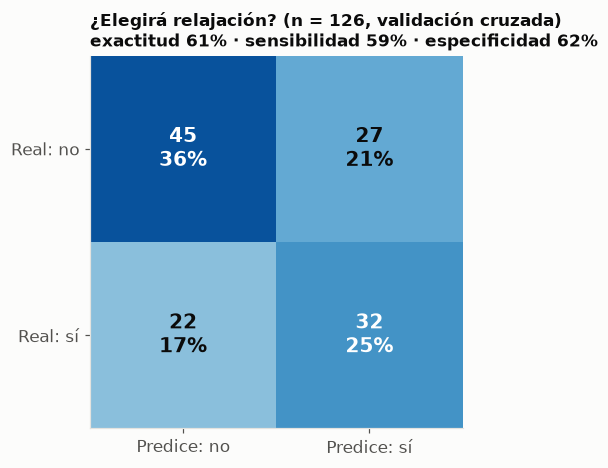

In [3]:
def dibujar_confusion(ax, cm, etiquetas, titulo):
    total = cm.sum()
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=cm.max() * 1.15)
    for i in range(2):
        for j in range(2):
            color = 'white' if cm[i, j] > cm.max() * 0.6 else TEXTO
            ax.text(j, i, f'{cm[i, j]}\n{cm[i, j] / total:.0%}', ha='center', va='center', fontsize=13, color=color, fontweight='bold')
    ax.set_xticks([0, 1], [f'Predice: {e}' for e in etiquetas]); ax.set_yticks([0, 1], [f'Real: {e}' for e in etiquetas])
    ax.grid(False); ax.set_title(titulo, fontsize=11)

fig, ax = plt.subplots(figsize=(5.2, 4.4))
dibujar_confusion(ax, cm, ['no', 'sí'], f'¿Elegirá relajación? (n = {len(d)}, validación cruzada)\n'
                  f'exactitud {metricas["exactitud"]:.0%} · sensibilidad {metricas["sensibilidad (recall)"]:.0%} · especificidad {metricas["especificidad"]:.0%}')
guardar(fig, '08_matriz_confusion_relajacion');

## 2. Curva ROC con IC 95 %

AUC = 0.637, IC 95 % [0.536, 0.732]


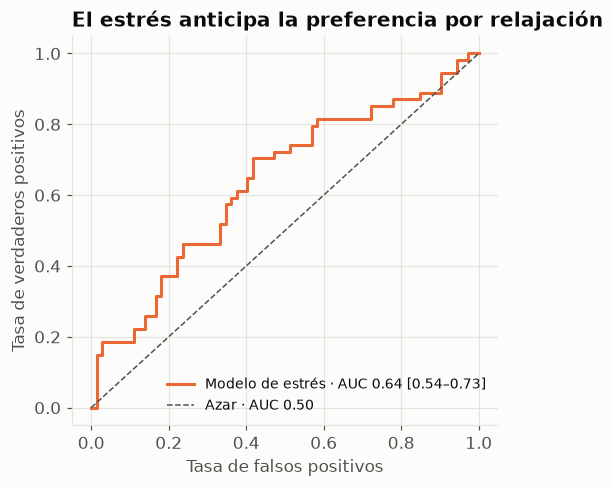

In [4]:
auc = roc_auc_score(y, prob)
rng = np.random.default_rng(0)
boot = []
for _ in range(2000):
    i = rng.integers(0, len(y), len(y))
    if y[i].min() != y[i].max():
        boot.append(roc_auc_score(y[i], prob[i]))
lo, hi = np.percentile(boot, [2.5, 97.5])
fpr, tpr, _ = roc_curve(y, prob)
fig, ax = plt.subplots(figsize=(5, 4.6))
ax.plot(fpr, tpr, color=SERIES[1], linewidth=2, label=f'Modelo de estrés · AUC {auc:.2f} [{lo:.2f}–{hi:.2f}]')
ax.plot([0, 1], [0, 1], color=TEXTO_2, linestyle='--', linewidth=1, label='Azar · AUC 0.50')
ax.set_xlabel('Tasa de falsos positivos'); ax.set_ylabel('Tasa de verdaderos positivos')
ax.legend(frameon=False, loc='lower right', fontsize=9)
ax.set_title('El estrés anticipa la preferencia por relajación')
guardar(fig, '08_roc_relajacion');
print(f'AUC = {auc:.3f}, IC 95 % [{lo:.3f}, {hi:.3f}]')

## 3. Calibración: probabilidad del modelo vs. lo observado

,estres,predicha,observada,n,ic
quintil,,,,,
0,26.852,0.262,0.296,27,0.172
1,41.027,0.352,0.269,26,0.170
2,51.131,0.426,0.538,26,0.192
3,64.668,0.530,0.484,31,0.176
4,79.519,0.641,0.625,16,0.237


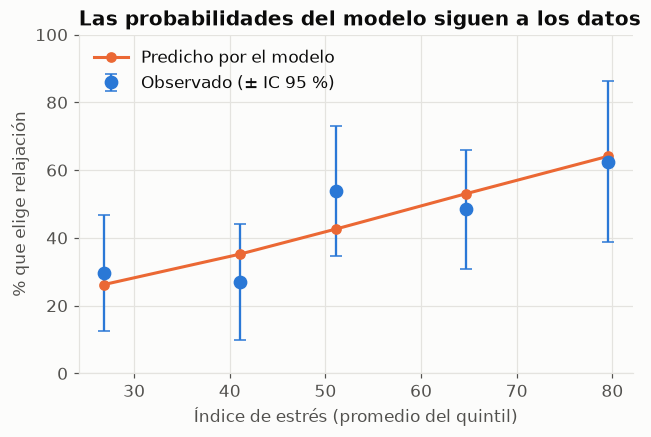

In [5]:
d['quintil'] = pd.qcut(d['estres_0_100'], 5, labels=False, duplicates='drop')
cal = d.assign(prob=prob).groupby('quintil').agg(estres=('estres_0_100', 'mean'), predicha=('prob', 'mean'),
                                                  observada=('pref_relajacion', 'mean'), n=('pref_relajacion', 'size'))
cal['ic'] = 1.96 * np.sqrt(cal['observada'] * (1 - cal['observada']) / cal['n'])
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.errorbar(cal['estres'], cal['observada'] * 100, yerr=cal['ic'] * 100, fmt='o', color=SERIES[0], markersize=8,
            capsize=4, label='Observado (± IC 95 %)')
ax.plot(cal['estres'], cal['predicha'] * 100, color=SERIES[1], linewidth=2, marker='o', markersize=6, label='Predicho por el modelo')
ax.set_xlabel('Índice de estrés (promedio del quintil)'); ax.set_ylabel('% que elige relajación')
ax.set_ylim(0, 100); ax.legend(frameon=False, loc='upper left')
ax.set_title('Las probabilidades del modelo siguen a los datos')
guardar(fig, '08_calibracion_relajacion');
cal.round(3)

## 4. Matriz de confusión del recomendador (top 3 tipos por persona)

Para cada persona, fuera de muestra, se recomiendan 3 de los 8 tipos de experiencia. Cada par persona × tipo cuenta como recomendado/no y elegido/no.
* **Modelo final:** popularidad más el efecto del estrés, ajustado solo con los datos de entrenamiento.
* **Popularidad:** los 3 tipos más elegidos.
* **Azar:** 3 tipos al azar.

,precisión@3,recall@3,exactitud,nDCG@3
Azar,0.378,0.372,0.528,0.417
Popularidad,0.540,0.531,0.649,0.647
Modelo final (popularidad + estrés),0.561,0.552,0.665,0.659


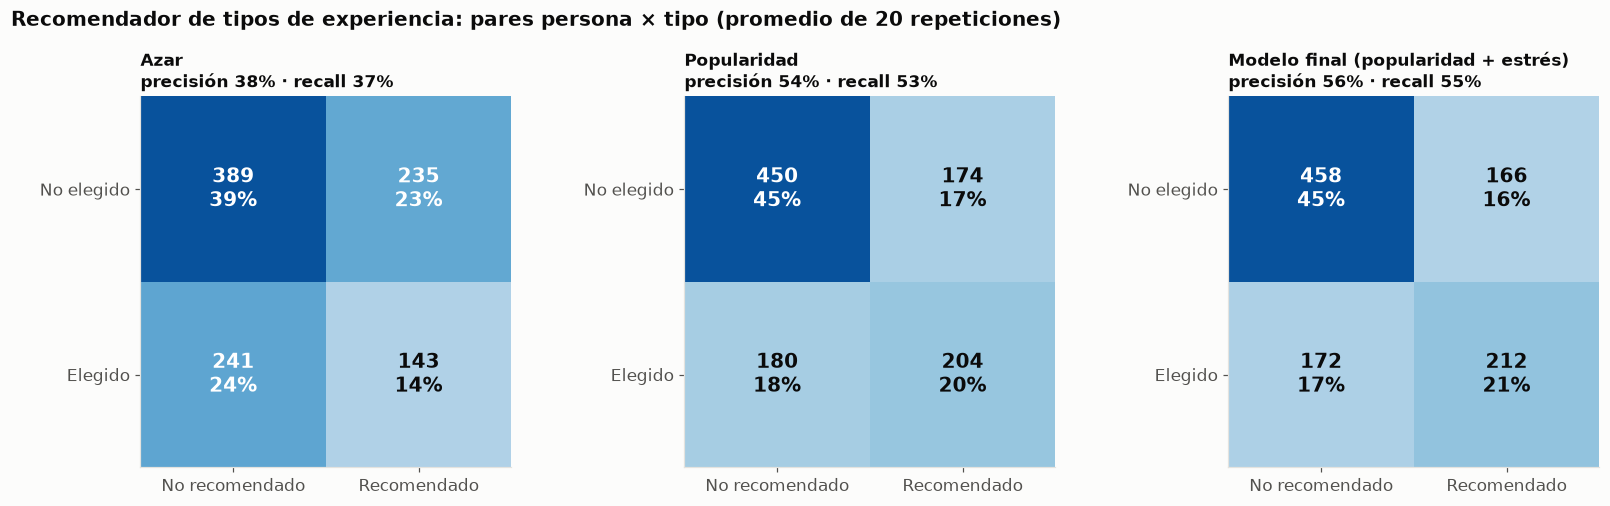

In [6]:
Y = d[PREFERENCIAS].to_numpy()
idx_rel = PREFERENCIAS.index('pref_relajacion')
acum = {m: np.zeros((2, 2), dtype=int) for m in ['Azar', 'Popularidad', 'Modelo final (popularidad + estrés)']}
ndcg = {m: [] for m in acum}
rng = np.random.default_rng(1); reps = 20
for r in range(reps):
    for tr, te in KFold(5, shuffle=True, random_state=r).split(d):
        pop = Y[tr].mean(axis=0)
        lr = LogisticRegression().fit(X[tr], Y[tr, idx_rel])
        for i in te:
            modelo = pop.copy(); modelo[idx_rel] = lr.predict_proba(X[i:i + 1])[0, 1]
            for nombre, s in [('Azar', rng.random(8)), ('Popularidad', pop + rng.random(8) * 1e-9), ('Modelo final (popularidad + estrés)', modelo)]:
                rec = np.zeros(8, dtype=int); rec[np.argsort(-s)[:3]] = 1
                acum[nombre] += confusion_matrix(Y[i], rec, labels=[0, 1])
                ndcg[nombre].append(ndcg_at_k(s, Y[i]))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
resumen = {}
for ax, (nombre, m) in zip(axes, acum.items()):
    m = (m / reps).round().astype(int)
    tn, fp, fn, tp = m.ravel()
    resumen[nombre] = {'precisión@3': tp / (tp + fp), 'recall@3': tp / (tp + fn), 'exactitud': (tp + tn) / m.sum(), 'nDCG@3': np.nanmean(ndcg[nombre])}
    dibujar_confusion(ax, m, ['no', 'sí'], f'{nombre}\nprecisión {resumen[nombre]["precisión@3"]:.0%} · recall {resumen[nombre]["recall@3"]:.0%}')
    ax.set_xticks([0, 1], ['No recomendado', 'Recomendado']); ax.set_yticks([0, 1], ['No elegido', 'Elegido'])
fig.suptitle('Recomendador de tipos de experiencia: pares persona × tipo (promedio de 20 repeticiones)', fontweight='bold', x=0.01, ha='left')
fig.tight_layout()
guardar(fig, '08_matriz_confusion_recomendador');
pd.DataFrame(resumen).T.round(3)

## 5. Curva de aprendizaje: ¿mejora el ML con más personas?

Logística · estrés         Logística · perfil completo        
                  mean     std                        mean     std
n                                                                 
40             -0.0077  0.0194                     -0.0435  0.0349
60             -0.0095  0.0163                     -0.0560  0.0292
80             -0.0115  0.0174                     -0.0509  0.0197
100            -0.0113  0.0143                     -0.0584  0.0181
120            -0.0095  0.0148                     -0.0535  0.0165
126            -0.0066  0.0086                     -0.0553  0.0119

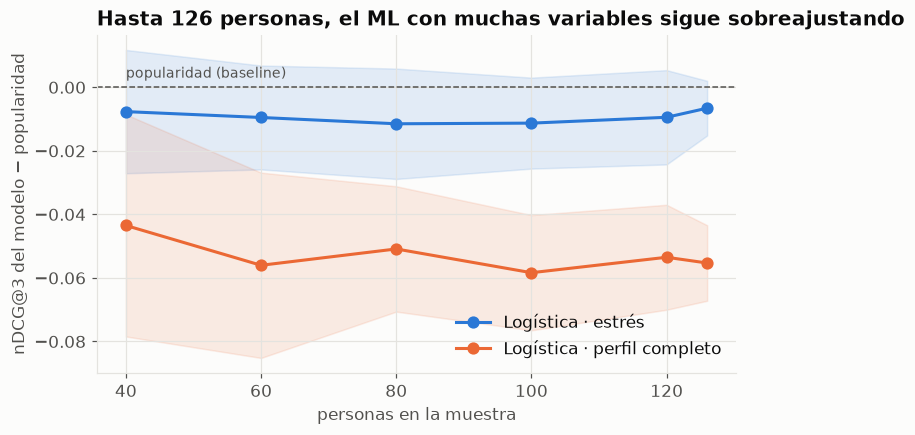

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from encuesta_etl import SINTOMAS, ESTRESORES
PERFIL = ['estres_0_100', 'bienestar_0_100', 'satisfaccion', 'edad_ord'] + SINTOMAS + ESTRESORES

def ndcg_cv(datos, features, semilla):
    Yd = datos[PREFERENCIAS].to_numpy(); res = []
    for tr, te in KFold(5, shuffle=True, random_state=semilla).split(datos):
        if features is None:
            s = np.tile(Yd[tr].mean(axis=0), (len(te), 1))
        else:
            cols = []
            for k in range(8):
                if Yd[tr, k].min() == Yd[tr, k].max():
                    cols.append(np.full(len(te), Yd[tr, k].mean())); continue
                m = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
                cols.append(m.fit(datos.iloc[tr][features], Yd[tr, k]).predict_proba(datos.iloc[te][features])[:, 1])
            s = np.column_stack(cols)
        res += [ndcg_at_k(s[j], Yd[i]) for j, i in enumerate(te)]
    return np.nanmean(res)

tamanos = [40, 60, 80, 100, 120, len(d)]
filas = []
for n in tamanos:
    for r in range(15):
        sub = d.sample(n, random_state=r, replace=False).reset_index(drop=True)
        base = ndcg_cv(sub, None, r)
        filas.append({'n': n, 'Logística · estrés': ndcg_cv(sub, ['estres_0_100', 'bienestar_0_100'], r) - base,
                      'Logística · perfil completo': ndcg_cv(sub, PERFIL, r) - base})
curva = pd.DataFrame(filas).groupby('n').agg(['mean', 'std'])
fig, ax = plt.subplots(figsize=(7.5, 4))
for color, modelo in zip([SERIES[0], SERIES[1]], ['Logística · estrés', 'Logística · perfil completo']):
    media, de = curva[(modelo, 'mean')], curva[(modelo, 'std')]
    ax.plot(curva.index, media, marker='o', color=color, linewidth=2, markersize=7, label=modelo)
    ax.fill_between(curva.index, media - de, media + de, color=color, alpha=0.12)
ax.axhline(0, color=TEXTO_2, linestyle='--', linewidth=1)
ax.text(curva.index.min(), 0.003, 'popularidad (baseline)', color=TEXTO_2, fontsize=9)
ax.set_xlabel('personas en la muestra'); ax.set_ylabel('nDCG@3 del modelo − popularidad')
ax.legend(frameon=False, loc='lower right')
ax.set_title('Hasta 126 personas, el ML con muchas variables sigue sobreajustando')
guardar(fig, '08_curva_aprendizaje');
curva.round(4)

## 6. Análisis de potencia: personas necesarias para detectar cada efecto

Para una regresión logística con un predictor continuo (Hsieh, 1989): n = (z₁₋α/₂ + z₁₋β)² / [p(1−p)·ln(OR)²], con α = 0.05 y potencia del 80 %, usando el OR y la prevalencia observados.

,preferencia,prevalencia,or_por_de,q_fdr,n_necesario
2,pref_relajacion,0.429,1.740,0.0408,105
4,pref_cultural,0.325,1.213,0.7160,960
3,pref_hospedaje_tranquilo,0.421,1.194,0.7160,1025
0,pref_cascadas_rios,0.651,1.145,0.7160,1885
5,pref_gastronomia,0.246,1.152,0.7160,2114
6,pref_baja_intensidad,0.222,1.143,0.7160,2544
7,pref_comunidades,0.159,0.919,0.8350,8227
1,pref_caminatas,0.595,1.035,0.8484,27523


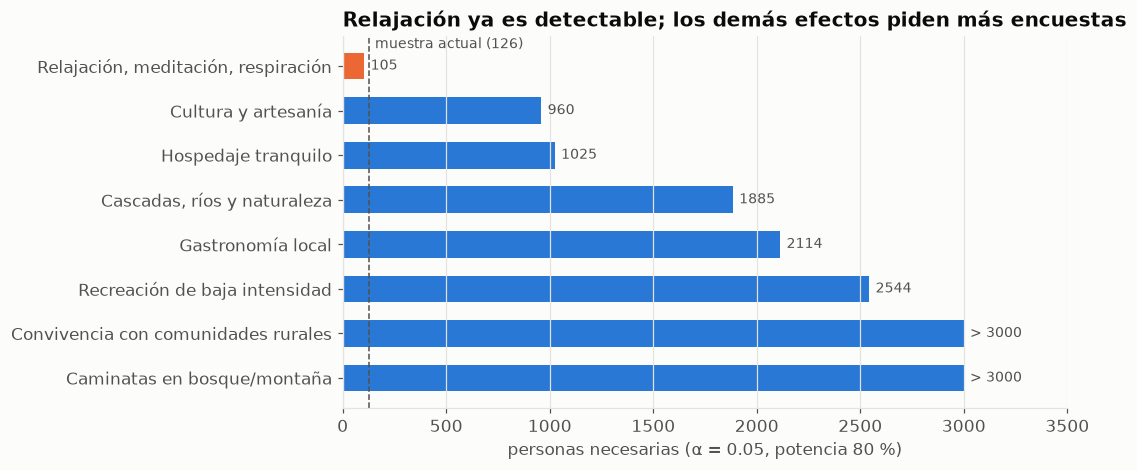

In [8]:
from modelo_preferencias import estimar_efectos
ef = estimar_efectos(df)
z = norm.ppf(0.975) + norm.ppf(0.80)
ef['n_necesario'] = [math.ceil(z ** 2 / (p * (1 - p) * math.log(o) ** 2)) if abs(math.log(o)) > 1e-6 else np.inf
                     for p, o in zip(ef['prevalencia'], ef['or_por_de'])]
ef = ef.sort_values('n_necesario')
fig, ax = plt.subplots(figsize=(8.5, 4.4))
valores = ef['n_necesario'].clip(upper=3000)
colores = [SERIES[1] if v <= len(d) else SERIES[0] for v in ef['n_necesario']]
ax.barh([ETIQUETAS_PREF[p] for p in ef['preferencia']][::-1], valores[::-1], color=colores[::-1], height=0.6)
ax.axvline(len(d), color=TEXTO_2, linestyle='--', linewidth=1)
ax.text(len(d) + 30, len(ef) - 0.6, f'muestra actual ({len(d)})', color=TEXTO_2, fontsize=9)
for i, v in enumerate(ef['n_necesario'][::-1]):
    ax.text(min(v, 3000) + 30, i, '> 3000' if v > 3000 else f'{int(v)}', va='center', color=TEXTO_2, fontsize=9)
ax.set_xlim(0, 3500); ax.set_xlabel('personas necesarias (α = 0.05, potencia 80 %)'); ax.grid(axis='y', visible=False)
ax.set_title('Relajación ya es detectable; los demás efectos piden más encuestas')
guardar(fig, '08_potencia_por_tipo');
ef[['preferencia', 'prevalencia', 'or_por_de', 'q_fdr', 'n_necesario']]

## 7. Flujo completo del sistema

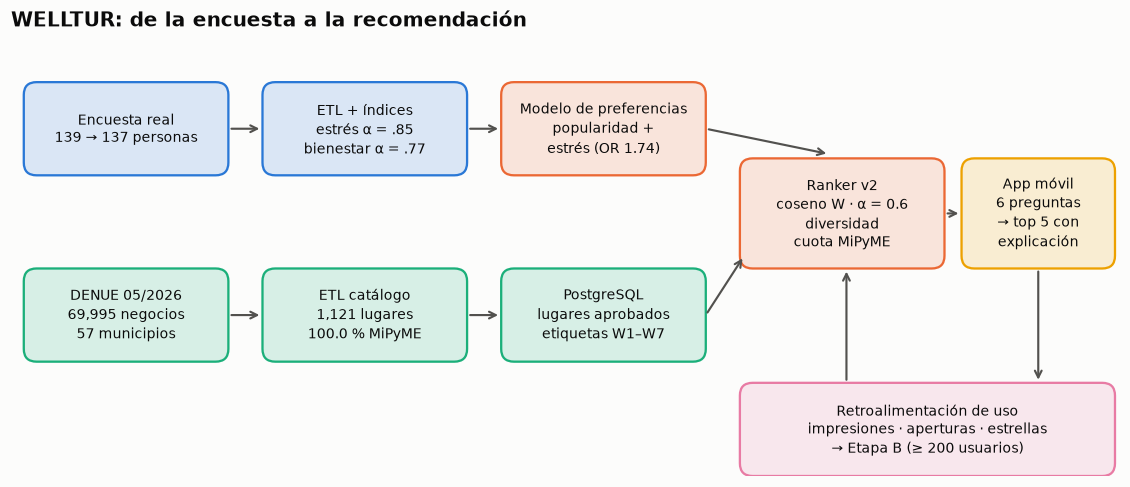

In [9]:
import json
fig, ax = plt.subplots(figsize=(13, 5.2)); ax.set_xlim(0, 13); ax.set_ylim(0, 5.2); ax.axis('off')
def caja(x, y, texto, color, w=2.3, h=1.0):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05,rounding_size=0.15', facecolor=color, edgecolor='none', alpha=0.16))
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05,rounding_size=0.15', facecolor='none', edgecolor=color, linewidth=1.5))
    ax.text(x + w / 2, y + h / 2, texto, ha='center', va='center', fontsize=9, color=TEXTO, linespacing=1.4)
def flecha(x1, y1, x2, y2):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle='->', color=TEXTO_2, lw=1.4))
caja(0.2, 3.6, 'Encuesta real\n139 → 137 personas', SERIES[0])
caja(3.0, 3.6, 'ETL + índices\nestrés α = .85\nbienestar α = .77', SERIES[0])
caja(5.8, 3.6, 'Modelo de preferencias\npopularidad +\nestrés (OR 1.74)', SERIES[1])
from denue_etl import SALIDA as _CAT
_log = json.loads(_CAT.with_suffix('.log.json').read_text(encoding='utf-8'))
_ed = _log['edicion_denue']; _ed = f'{_ed[:2]}/20{_ed[2:]}' if len(_ed) == 4 else _ed
caja(0.2, 1.4, f"DENUE {_ed}\n{_log['registros_region']:,} negocios\n57 municipios", SERIES[2])
caja(3.0, 1.4, f"ETL catálogo\n{_log['catalogo_final']:,} lugares\n{_log['mipyme_pct']:.1f} % MiPyME", SERIES[2])
caja(5.8, 1.4, 'PostgreSQL\nlugares aprobados\netiquetas W1–W7', SERIES[2])
caja(8.6, 2.5, 'Ranker v2\ncoseno W · α = 0.6\ndiversidad\ncuota MiPyME', SERIES[1], h=1.2)
caja(11.2, 2.5, 'App móvil\n6 preguntas\n→ top 5 con\nexplicación', SERIES[3], w=1.7, h=1.2)
caja(8.6, 0.05, 'Retroalimentación de uso\nimpresiones · aperturas · estrellas\n→ Etapa B (≥ 200 usuarios)', SERIES[4], w=4.3, h=1.0)
flecha(2.55, 4.1, 2.95, 4.1); flecha(5.35, 4.1, 5.75, 4.1); flecha(8.15, 4.1, 9.6, 3.8)
flecha(2.55, 1.9, 2.95, 1.9); flecha(5.35, 1.9, 5.75, 1.9); flecha(8.15, 1.9, 8.6, 2.6)
flecha(10.95, 3.1, 11.15, 3.1)
flecha(12.05, 2.45, 12.05, 1.1)
flecha(9.8, 1.1, 9.8, 2.45)
ax.set_title('WELLTUR: de la encuesta a la recomendación', loc='left')
guardar(fig, '08_flujo_sistema');

## Lectura para la defensa
* **Matriz de confusión y ROC:** el estrés anticipa la preferencia por relajación por encima del azar (AUC con IC 95 % que no toca 0.5). Es una señal modesta pero real, medida fuera de muestra.
* **Calibración:** las probabilidades del modelo siguen a lo observado en cada quintil de estrés; no exagera el efecto.
* **Recomendador:** el modelo final recomienda tipos elegidos con mucha más precisión que el azar e iguala a la popularidad, agregando personalización solo donde hay evidencia.
* **Curva de aprendizaje:** entre 40 y 126 personas el modelo con todo el perfil queda ~0.05 por debajo de la popularidad sin mejorar; el de estrés queda cerca de 0. La muestra actual está lejos del tamaño que necesita un modelo con muchas variables, por eso se eligió el modelo simple.
* **Potencia:** el efecto de relajación necesita ~105 personas y ya se detecta con 126; los demás efectos (si existen) requieren de ~1,000 a más de 3,000 personas. Eso convierte la siguiente fase en un plan medible: más encuestas y retroalimentación de la app.